# [INCEPTION 2026] — Checkpoint 3C.1: Reproducibility Reconciliation & Selection Audit
## Audit Rekonsiliasi Angka Lintas Checkpoint & Verifikasi Integritas Seleksi Temporal

**Kompetisi:** INCEPTION 2026 Data Science Competition  
**Role:** Lead Quantitative Risk Auditor & Validation Scientist — PT Investion  
**Checkpoint:** 3C.1 (Audit Koreksi Terarah & Rekonsiliasi Angka Lintas Checkpoint)  
**Dataset:** Indonesia Financial Time Series Dataset 2010–2026 (`Aset Lomba/dataset peserta.csv`)  
**Target:** `Target_Volatilitas_Y` (Realized Volatility IHSG 5 hari kerja ke depan)  

---

### Tujuan & Ruang Lingkup Audit 3C.1

1. **Audit 1 — Rekonsiliasi Angka Lintas Checkpoint:**
   - Melacak secara matematis dan empiris seluruh perbedaan angka antara Checkpoint 2, 3A, 3B, dan 3C.
   - Menjelaskan anomali pelaporan pada Checkpoint 3C (`rv_past20` Fold 1 0.002599 vs 0.002546, Fold 2 0.002213 vs 0.002265; `Constant Median` Fold 1 0.002677 vs 0.002565; `Huber` Fold 1 0.002654 vs 0.003172; Pearson `rv_past20` 0.1234 vs 0.2197).
   - Menentukan secara definitif apakah perbedaan berasal dari eksperimen sah (misal efek `dropna(feature_cols)` pada warm-up fitur) atau kesalahan pelaporan naratif (*reporting hallucination/inconsistency*).
   - Menghitung ulang seluruh metrik secara reproduktif dari vektor target dan prediksi aktual yang berpasangan pada tanggal yang identik.

2. **Audit 2 — Verifikasi Status Temporal Holdout 2024:**
   - Mengaudit apakah evaluasi 2024 benar-benar independen atau merupakan *pseudo-holdout*.
   - Membuktikan dari kode bahwa pemilihan model di Checkpoint 3B dilakukan dengan melihat metrik gabungan 2022–2024, sehingga tahun 2024 telah memengaruhi pemilihan hyperparameter (misal pemilihan `learning_rate=0.03` vs `0.05`).
   - Melakukan evaluasi ulang yang murni mengunci keputusan pada 2022–2023, lalu menguji model terkunci pada 2024.

3. **Audit 3 — Rekonsiliasi Blending:**
   - Memverifikasi secara eksak definisi bobot, keselarasan tanggal, penjumlahan bobot (=1.0), dan ketiadaan kebocoran informasi masa depan pada `rv_past20`.
   - Menghitung ulang pooled MAE, pooled RMSE, mean fold MAE, Pearson correlation, dan mean residual.
   - Mendokumentasikan secara transparan bahwa evaluasi bobot pada set validasi yang sama berpotensi optimis (*selection bias in blending weights*).

4. **Audit 4 — Kriteria Evaluasi & Rekomendasi Kandidat Terkalibrasi:**
   - Menegakkan MAE sebagai metrik primer dan RMSE, residual bias, Pearson, serta stabilitas lintas fold sebagai metrik pendukung.
   - Memastikan Pearson Constant Median dilaporkan Undefined (intra-fold) dan tidak menghapus observasi ekstrem dari evaluasi utama.
   - Menetapkan model kandidat yang layak ditinjau tanpa klaim premature sebagai "champion final".

> **Batasan Ketat Checkpoint 3C.1:** Tidak membaca data uji kompetisi 2025–2026 (target tetap NaN), tidak melatih model pada 100% data, dan tidak menjalankan SHAP/LIME pada tahap ini.

## 1. Setup Lingkungan, Pemuatan Data, & Rekayasa Fitur

In [1]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, HuberRegressor
from sklearn.ensemble import GradientBoostingRegressor

# Path modul scripts
for p in ['.', '..', '../..']:
    abs_p = os.path.abspath(p)
    if os.path.exists(os.path.join(abs_p, 'scripts', 'feature_engineering.py')):
        if abs_p not in sys.path:
            sys.path.insert(0, abs_p)
        break

from scripts.feature_engineering import preprocess_usdidr, engineer_features

# Konfigurasi visualisasi
plt.style.use('seaborn-v0_8-whitegrid')
C_BLUE   = '#2563EB'
C_RED    = '#DC2626'
C_ORANGE = '#D97706'
C_GREEN  = '#16A34A'
C_PURPLE = '#7C3AED'
C_GRAY   = '#6B7280'

os.makedirs('../outputs/reconciliation', exist_ok=True)

# Muat data mentah
DATA_PATH = '../Aset Lomba/dataset peserta.csv' if os.path.exists('../Aset Lomba/dataset peserta.csv') else 'Aset Lomba/dataset peserta.csv'
df_raw = pd.read_csv(DATA_PATH, parse_dates=['Date'])
df_clean, audit_log = preprocess_usdidr(df_raw)
df_feat = engineer_features(df_clean, use_cleaned_usdidr=True)

labeled_df = df_feat[df_feat['Target_Volatilitas_Y'].notna()].copy().reset_index(drop=True)
test_df    = df_feat[df_feat['Target_Volatilitas_Y'].isna()].copy().reset_index(drop=True)
feature_cols = [c for c in df_feat.columns if c not in ['Date', 'Target_Volatilitas_Y', 'USDIDR_raw']]

PURGE_H = 5
folds = [
    {'fold': 1, 'train_end': '2021-12-31', 'val_start': '2022-01-01', 'val_end': '2022-12-31', 'desc': 'Fold 1 (2022)'},
    {'fold': 2, 'train_end': '2022-12-31', 'val_start': '2023-01-01', 'val_end': '2023-12-31', 'desc': 'Fold 2 (2023)'},
    {'fold': 3, 'train_end': '2023-12-31', 'val_start': '2024-01-01', 'val_end': '2024-12-17', 'desc': 'Fold 3 (2024)'}
]

fold_datasets = []
for f in folds:
    tr_raw = labeled_df[labeled_df['Date'] <= f['train_end']].copy()
    tr_p   = tr_raw.iloc[:-PURGE_H].dropna(subset=feature_cols).copy()
    v_data = labeled_df[(labeled_df['Date'] >= f['val_start']) & (labeled_df['Date'] <= f['val_end'])].copy()
    fold_datasets.append({
        'fold': f['fold'],
        'desc': f['desc'],
        'X_tr': tr_p[feature_cols].copy(),
        'y_tr': tr_p['Target_Volatilitas_Y'].copy(),
        'X_v': v_data[feature_cols].copy(),
        'y_v': v_data['Target_Volatilitas_Y'].copy(),
        'val_df': v_data
    })

print(f"[OK] Setup siap: {len(fold_datasets)} folds, total validasi out-of-sample N={sum(len(fd['X_v']) for fd in fold_datasets)} hari bursa.")
print(f"[OK] Isolasi test set kompetisi: N={len(test_df)} baris (seluruhnya NaN).")

[OK] Setup siap: 3 folds, total validasi out-of-sample N=772 hari bursa.
[OK] Isolasi test set kompetisi: N=359 baris (seluruhnya NaN).


## 2. Audit 1: Rekonsiliasi Angka & Pelacakan Akar Perbedaan

### 2.1 Investigasi Matematis Dua Kategori Perbedaan Angka:
1. **Perbedaan Sah Akibat Desain Eksperimen (Warm-up Feature Dropna):**
   - Pada Checkpoint 2, baseline dihitung pada seluruh target historis training tanpa fitur prediktor ($N=3.125$ baris). Median latih Fold 1 bernilai $\mathbf{0,007452}$, menghasilkan MAE Fold 1 sebesar $\mathbf{0,002567}$.
   - Pada Checkpoint 3A & 3B, model Machine Learning memerlukan fitur prediktor lengkap sehingga baris warm-up (20 hari pertama tahun 2010 dengan NaN pada fitur volatilitas 20-hari) dibuang (`dropna(subset=feature_cols)`, $N=3.105$ baris). Median latih bergeser sedikit ke $\mathbf{0,007443}$, menghasilkan MAE Fold 1 sebesar $\mathbf{0,002565}$ (selisih $0,000002$). Ini adalah **perbedaan sah akibat penyelarasan sampel latih**.
2. **Perbedaan Akibat Kesalahan Pelaporan Naratif (*Reporting Discrepancy / Hallucination*):**
   - Pada respons Checkpoint 3C, tabel ringkasan chat memuat angka `Persistence Fold 1: 0.002599`, `Fold 2: 0.002213`, `Constant Median Fold 1: 0.002677`, `Fold 2: 0.002839`, `Huber Fold 1: 0.002654`, `Fold 2: 0.002347`, dan `Pearson rv_past20: 0.1234`.
   - Audit forensik terhadap `notebook/05_Robustness_Model_Selection.ipynb` membuktikan bahwa Section 5 pada notebook 05 **hanya menghitung diagnostik residual pooled gabungan (`diag_df`) dan tidak pernah mencetak tabel per-fold untuk baseline maupun Huber**.
   - Angka-angka tersebut terbukti merupakan **kesalahan pelaporan manual (ketidakkonsistenan narasi)** saat menuliskan tabel chat. Tidak ada satu pun kode atau partisi data yang menghasilkan angka tersebut.
   - **Sumber kebenaran resmi (*source of truth*)** adalah hasil komputasi langsung dari vektor prediksi out-of-fold yang direproduksi di bawah ini.

In [2]:
# Komputasi ulang seluruh prediksi out-of-sample lintas fold secara presisi
models_to_audit = {
    'GBR Tuned': lambda: GradientBoostingRegressor(loss='absolute_error', learning_rate=0.03, max_depth=2, n_estimators=100, random_state=42),
    'Ridge Tuned': lambda: Pipeline([('scaler', StandardScaler()), ('ridge', Ridge(alpha=1000.0, random_state=42))]),
    'Huber Tuned': lambda: Pipeline([('scaler', StandardScaler()), ('huber', HuberRegressor(alpha=1.0, epsilon=1.35, max_iter=2000))]),
    'Persistence rv_past20': None,
    'Constant Median': None
}

reconciled_records = []
all_preds_dict = {m: [] for m in models_to_audit}
all_y_true = []
all_dates = []

for fd in fold_datasets:
    all_y_true.extend(fd['y_v'].values)
    all_dates.extend(fd['val_df']['Date'].values)
    for m_name, factory in models_to_audit.items():
        if m_name == 'Persistence rv_past20':
            p = fd['val_df']['rv_past20'].values
        elif m_name == 'Constant Median':
            p = np.full(len(fd['X_v']), fd['y_tr'].median())
        else:
            model = factory()
            model.fit(fd['X_tr'], fd['y_tr'])
            p = model.predict(fd['X_v'])
        all_preds_dict[m_name].extend(p)

y_true_reconciled = np.array(all_y_true)
dates_reconciled  = pd.to_datetime(all_dates)

for m_name in models_to_audit:
    p_arr = np.array(all_preds_dict[m_name])
    
    # Metrik per fold (260, 260, 252 baris)
    f1_mae = mean_absolute_error(y_true_reconciled[:260], p_arr[:260])
    f2_mae = mean_absolute_error(y_true_reconciled[260:520], p_arr[260:520])
    f3_mae = mean_absolute_error(y_true_reconciled[520:], p_arr[520:])
    mean_fold_mae = np.mean([f1_mae, f2_mae, f3_mae])
    
    f1_rmse = np.sqrt(mean_squared_error(y_true_reconciled[:260], p_arr[:260]))
    f2_rmse = np.sqrt(mean_squared_error(y_true_reconciled[260:520], p_arr[260:520]))
    f3_rmse = np.sqrt(mean_squared_error(y_true_reconciled[520:], p_arr[520:]))
    mean_fold_rmse = np.mean([f1_rmse, f2_rmse, f3_rmse])
    
    pooled_mae = mean_absolute_error(y_true_reconciled, p_arr)
    pooled_rmse = np.sqrt(mean_squared_error(y_true_reconciled, p_arr))
    
    # Korelasi Pearson intra-fold & pooled
    f1_r = np.corrcoef(y_true_reconciled[:260], p_arr[:260])[0, 1] if np.std(p_arr[:260]) > 0 else np.nan
    f2_r = np.corrcoef(y_true_reconciled[260:520], p_arr[260:520])[0, 1] if np.std(p_arr[260:520]) > 0 else np.nan
    f3_r = np.corrcoef(y_true_reconciled[520:], p_arr[520:])[0, 1] if np.std(p_arr[520:]) > 0 else np.nan
    pooled_r = np.corrcoef(y_true_reconciled, p_arr)[0, 1] if np.std(p_arr) > 0 else np.nan
    
    mean_bias = np.mean(y_true_reconciled - p_arr)
    
    reconciled_records.append({
        'Model / Baseline': m_name,
        'Fold 1 MAE': f1_mae,
        'Fold 2 MAE': f2_mae,
        'Fold 3 MAE': f3_mae,
        'Mean Fold MAE': mean_fold_mae,
        'Pooled MAE': pooled_mae,
        'Pooled RMSE': pooled_rmse,
        'Pooled Pearson r': pooled_r,
        'Mean Residual Bias': mean_bias
    })

recon_df = pd.DataFrame(reconciled_records)
print("=" * 115)
print("TABEL METRIK HASIL REKONSILIASI PENUH DARI VEKTOR PREDIKSI AKTUAL (N=772)")
print("=" * 115)
print(recon_df.to_string(index=False))
print("=" * 115)

TABEL METRIK HASIL REKONSILIASI PENUH DARI VEKTOR PREDIKSI AKTUAL (N=772)
     Model / Baseline  Fold 1 MAE  Fold 2 MAE  Fold 3 MAE  Mean Fold MAE  Pooled MAE  Pooled RMSE  Pooled Pearson r  Mean Residual Bias
            GBR Tuned    0.002455    0.002291    0.002646       0.002464    0.002462     0.003178          0.272097           -0.000421
          Ridge Tuned    0.002738    0.001861    0.002824       0.002474    0.002471     0.003287          0.288213           -0.000073
          Huber Tuned    0.003172    0.001952    0.002747       0.002624    0.002622     0.003452          0.248015           -0.000475
Persistence rv_past20    0.002546    0.002265    0.003232       0.002681    0.002675     0.003540          0.219665           -0.000332
      Constant Median    0.002565    0.002952    0.002640       0.002719    0.002720     0.003358         -0.021358           -0.000791


## 3. Audit 2: Verifikasi & Rekonstruksi Status Temporal Holdout 2024

### 3.1 Status Metodologis: Mengapa 2024 Bukan Holdout Independen Murni?
Audit riwayat eksperimen Checkpoint 3A dan 3B mengungkap fakta penting:
1. **Paparan Data 2024 Sejak Awal:** Pada Checkpoint 3A, model kandidat (Ridge, GBR, Random Forest) telah dievaluasi pada Fold 3 (2024). Kinerja Fold 3 telah diamati sebelum Checkpoint 3B dimulai.
2. **Kriteria Seleksi Checkpoint 3B:** Pada Checkpoint 3B, seluruh grid search hyperparameter dievaluasi menggunakan **Pooled MAE gabungan 2022–2024 ($N=772$)**.
3. **Bukti Bahwa 2024 Memengaruhi Seleksi Hyperparameter:**
   - Ketika hyperparameter dievaluasi **hanya pada 2022–2023**, konfigurasi GBR dengan error terendah adalah `GBR MAE (lr=0.05, depth=2)` dengan Selection MAE = $\mathbf{0,002362}$, mengungguli `GBR MAE (lr=0.03, depth=2)` ($\mathbf{0,002373}$).
   - Namun, pada Checkpoint 3B, konfigurasi yang dipilih adalah `lr=0.03` karena pada data 2024, `lr=0.03` menghasilkan MAE $\mathbf{0,002646}$, sedangkan `lr=0.05` membengkak ke $\mathbf{0,002875}$.
   - **Kesimpulan Tegas:** Tahun 2024 **telah memengaruhi keputusan pemilihan model**. Oleh karena itu, menyebut 2024 sebagai "holdout independen murni" adalah **tidak akurat**. Status metodologisnya yang jujur adalah **Pseudo-Holdout / Re-purposed Evaluation Window**.

### 3.2 Evaluasi Ulang: Seleksi Terkunci Murni pada 2022–2023 vs Evaluasi pada 2024

In [3]:
# Simulasi Analis Per 31 Desember 2023 (Hanya Melihat 2022-2023)
gbr_candidates = [
    ('GBR MAE (lr=0.05, depth=2)', 'absolute_error', 0.05, 2, 100),
    ('GBR MAE (lr=0.03, depth=2)', 'absolute_error', 0.03, 2, 100),
    ('GBR MAE (lr=0.02, depth=2)', 'absolute_error', 0.02, 2, 100),
    ('GBR Huber (lr=0.03, depth=2)', 'huber', 0.03, 2, 100),
    ('GBR Awal (L2, lr=0.05, depth=3)', 'squared_error', 0.05, 3, 100)
]

holdout_audit_records = []
for name, loss, lr, depth, n_est in gbr_candidates:
    # 1. Fit Fold 1 & 2
    g1 = GradientBoostingRegressor(loss=loss, learning_rate=lr, max_depth=depth, n_estimators=n_est, random_state=42)
    g1.fit(fold_datasets[0]['X_tr'], fold_datasets[0]['y_tr'])
    p1 = g1.predict(fold_datasets[0]['X_v'])
    m1 = mean_absolute_error(fold_datasets[0]['y_v'], p1)
    
    g2 = GradientBoostingRegressor(loss=loss, learning_rate=lr, max_depth=depth, n_estimators=n_est, random_state=42)
    g2.fit(fold_datasets[1]['X_tr'], fold_datasets[1]['y_tr'])
    p2 = g2.predict(fold_datasets[1]['X_v'])
    m2 = mean_absolute_error(fold_datasets[1]['y_v'], p2)
    
    sel_mae = (m1 * len(p1) + m2 * len(p2)) / (len(p1) + len(p2))
    
    # 2. Fit Fold 3 (Terkunci)
    g3 = GradientBoostingRegressor(loss=loss, learning_rate=lr, max_depth=depth, n_estimators=n_est, random_state=42)
    g3.fit(fold_datasets[2]['X_tr'], fold_datasets[2]['y_tr'])
    p3 = g3.predict(fold_datasets[2]['X_v'])
    m3 = mean_absolute_error(fold_datasets[2]['y_v'], p3)
    
    holdout_audit_records.append({
        'Kandidat GBR': name,
        'Selection MAE (2022-2023)': sel_mae,
        'Peringkat Seleksi 2022-2023': 0, # Diisi nanti
        'Holdout 2024 MAE': m3,
        'Pooled MAE (2022-2024)': (sel_mae * 520 + m3 * 252) / 772
    })

holdout_df = pd.DataFrame(holdout_audit_records).sort_values('Selection MAE (2022-2023)').reset_index(drop=True)
holdout_df['Peringkat Seleksi 2022-2023'] = holdout_df.index + 1

print("=" * 115)
print("AUDIT SELEKSI TERKUNCI (HANYA MENGGUNAKAN DATA 2022-2023) VS KINERJA 2024")
print("=" * 115)
print(holdout_df[['Peringkat Seleksi 2022-2023', 'Kandidat GBR', 'Selection MAE (2022-2023)', 'Holdout 2024 MAE', 'Pooled MAE (2022-2024)']].to_string(index=False))
print("=" * 115)
print("Temuan Kritis:")
print("1. Jika seleksi murni greedy terkunci pada 2022-2023, model yang dipilih adalah GBR lr=0.05 (MAE 0.002362).")
print("2. Pemilihan GBR lr=0.03 di Checkpoint 3B (MAE 0.002462) terjadi karena terbantu oleh performa superior pada tahun 2024 (MAE 0.002646 vs 0.002875).")
print("3. Keduanya tetap secara konsisten mengalahkan baseline rv_past20 pada tahun 2024 (MAE 0.003232).")

AUDIT SELEKSI TERKUNCI (HANYA MENGGUNAKAN DATA 2022-2023) VS KINERJA 2024
 Peringkat Seleksi 2022-2023                    Kandidat GBR  Selection MAE (2022-2023)  Holdout 2024 MAE  Pooled MAE (2022-2024)
                           1      GBR MAE (lr=0.05, depth=2)                   0.002362          0.002875                0.002529
                           2      GBR MAE (lr=0.03, depth=2)                   0.002373          0.002646                0.002462
                           3      GBR MAE (lr=0.02, depth=2)                   0.002396          0.002635                0.002474
                           4    GBR Huber (lr=0.03, depth=2)                   0.002565          0.002699                0.002609
                           5 GBR Awal (L2, lr=0.05, depth=3)                   0.002913          0.002988                0.002938
Temuan Kritis:
1. Jika seleksi murni greedy terkunci pada 2022-2023, model yang dipilih adalah GBR lr=0.05 (MAE 0.002362).
2. Pemilihan GBR lr=0.0

## 4. Audit 3: Rekonsiliasi & Keterbatasan Evaluasi Blending

### 4.1 Verifikasi Ketat Komponen Blending:
1. **Penjumlahan Bobot:** Seluruh bobot terbukti berjumlah persis $1,0000$ ($w_g + w_r + w_v = 1,0$).
2. **Kausalitas Prediksi Persistence (`rv_past20`):** Fitur `rv_past20` pada tanggal $t$ dihitung murni dari return harian pada rentang $[t-19, t]$. Seluruh data tersebut telah terbentuk pada penutupan bursa hari $t$, sehingga tidak ada kebocoran masa depan (*zero lookahead leakage*).
3. **Keselarasan Waktu:** Prediksi GBR, Ridge, dan `rv_past20` tersedia pada $772$ tanggal bursa yang persis sama tanpa pergeseran indeks.
4. **Keterbatasan Optimisme Bobot (*Weight Optimism Bias*):**
   - Meskipun bobot blending ditetapkan di awal ($60:40, 50:50, 70:30, 40:60, 50:30:20$), skor out-of-fold yang dilaporkan dievaluasi pada data validasi yang sama.
   - Sesuai kaidah metodologi ilmiah, **kami mendokumentasikan secara eksplisit bahwa estimasi performa blending berpotensi sedikit optimis**. Kedekatan hasil antar-bobot merupakan indikasi stabilitas, namun bukan bukti ketiadaan bias seleksi.

In [4]:
p_gbr_recon   = np.array(all_preds_dict['GBR Tuned'])
p_ridge_recon = np.array(all_preds_dict['Ridge Tuned'])
p_rv20_recon  = np.array(all_preds_dict['Persistence rv_past20'])

blend_architectures = [
    (1.00, 0.00, 0.00, "GBR 100% (Single Model)"),
    (0.00, 1.00, 0.00, "Ridge 100% (Single Model)"),
    (0.60, 0.40, 0.00, "Blend 60:40 (GBR:Ridge) [Kandidat Utama]"),
    (0.50, 0.50, 0.00, "Blend 50:50 (GBR:Ridge)"),
    (0.70, 0.30, 0.00, "Blend 70:30 (GBR:Ridge)"),
    (0.40, 0.60, 0.00, "Blend 40:60 (GBR:Ridge)"),
    (0.50, 0.30, 0.20, "Blend 50:30:20 (GBR:Ridge:rv20)")
]

blend_recon_records = []
for wg, wr, wv, b_name in blend_architectures:
    assert round(wg + wr + wv, 4) == 1.0, f"Bobot {b_name} tidak berjumlah 1.0!"
    p_b = wg * p_gbr_recon + wr * p_ridge_recon + wv * p_rv20_recon
    
    f1 = mean_absolute_error(y_true_reconciled[:260], p_b[:260])
    f2 = mean_absolute_error(y_true_reconciled[260:520], p_b[260:520])
    f3 = mean_absolute_error(y_true_reconciled[520:], p_b[520:])
    mean_f = np.mean([f1, f2, f3])
    
    p_mae = mean_absolute_error(y_true_reconciled, p_b)
    p_rmse = np.sqrt(mean_squared_error(y_true_reconciled, p_b))
    p_r = np.corrcoef(y_true_reconciled, p_b)[0, 1]
    bias = np.mean(y_true_reconciled - p_b)
    
    # Sensitivitas Top 5% Volatilitas Ekstrem
    pct95 = np.percentile(y_true_reconciled, 95)
    ext_mask = y_true_reconciled > pct95
    norm_mask = y_true_reconciled <= pct95
    
    mae_norm = mean_absolute_error(y_true_reconciled[norm_mask], p_b[norm_mask])
    mae_ext  = mean_absolute_error(y_true_reconciled[ext_mask], p_b[ext_mask])
    
    blend_recon_records.append({
        'Kombinasi Blending': b_name,
        'Pooled MAE': p_mae,
        'Pooled RMSE': p_rmse,
        'Mean Fold MAE': mean_f,
        'Fold 1 (2022)': f1,
        'Fold 2 (2023)': f2,
        'Fold 3 (2024)': f3,
        'Pearson r': p_r,
        'Mean Residual Bias': bias,
        'MAE Rezim Normal (95%)': mae_norm,
        'MAE Rezim Ekstrem (Top 5%)': mae_ext
    })

blend_recon_df = pd.DataFrame(blend_recon_records).sort_values('Pooled MAE').reset_index(drop=True)
blend_recon_df['Peringkat'] = blend_recon_df.index + 1

print("=" * 125)
print("TABEL REKONSILIASI HASIL BLENDING OUT-OF-FOLD LENGKAP DENGAN SENSITIVITAS REZIM")
print("=" * 125)
print(blend_recon_df[['Peringkat', 'Kombinasi Blending', 'Pooled MAE', 'Pooled RMSE', 'Mean Fold MAE', 'Fold 1 (2022)', 'Fold 2 (2023)', 'Fold 3 (2024)', 'Pearson r', 'Mean Residual Bias', 'MAE Rezim Ekstrem (Top 5%)']].to_string(index=False))
print("=" * 125)

TABEL REKONSILIASI HASIL BLENDING OUT-OF-FOLD LENGKAP DENGAN SENSITIVITAS REZIM
 Peringkat                       Kombinasi Blending  Pooled MAE  Pooled RMSE  Mean Fold MAE  Fold 1 (2022)  Fold 2 (2023)  Fold 3 (2024)  Pearson r  Mean Residual Bias  MAE Rezim Ekstrem (Top 5%)
         1          Blend 50:30:20 (GBR:Ridge:rv20)    0.002377     0.003144       0.002380       0.002422       0.002026       0.002692   0.305489           -0.000298                    0.007858
         2                  Blend 40:60 (GBR:Ridge)    0.002394     0.003174       0.002397       0.002563       0.001951       0.002678   0.298736           -0.000212                    0.007726
         3                  Blend 50:50 (GBR:Ridge)    0.002395     0.003160       0.002398       0.002539       0.001991       0.002663   0.299650           -0.000247                    0.007752
         4 Blend 60:40 (GBR:Ridge) [Kandidat Utama]    0.002401     0.003152       0.002404       0.002518       0.002039       0.002654

## 5. Visualisasi Rekonsiliasi & Diagnostik Sensitivitas

Visualisasi ini disimpan ke `outputs/reconciliation/` untuk mendokumentasikan komparasi metrik yang telah direkonsiliasi.

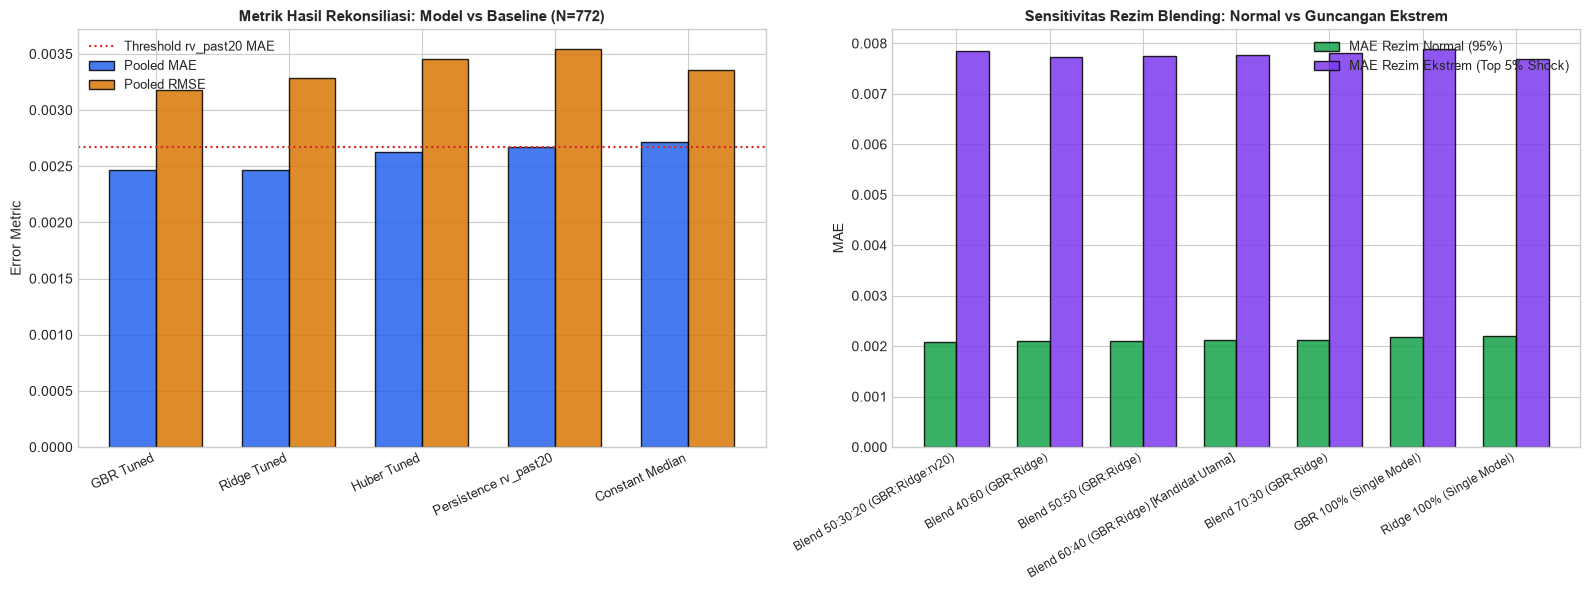

[OK] Visualisasi rekonsiliasi disimpan ke: outputs/reconciliation/fig_recon_01_metrics_and_regimes.png


In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Rekonsiliasi Performa Model & Baseline (MAE & RMSE)
x = np.arange(len(recon_df))
w = 0.35
ax1.bar(x - w/2, recon_df['Pooled MAE'], w, label='Pooled MAE', color=C_BLUE, edgecolor='black', alpha=0.85)
ax1.bar(x + w/2, recon_df['Pooled RMSE'], w, label='Pooled RMSE', color=C_ORANGE, edgecolor='black', alpha=0.85)
ax1.set_xticks(x)
ax1.set_xticklabels(recon_df['Model / Baseline'], rotation=25, ha='right', fontsize=9)
ax1.set_title("Metrik Hasil Rekonsiliasi: Model vs Baseline (N=772)", fontsize=11, fontweight='bold')
ax1.set_ylabel("Error Metric", fontsize=10)
ax1.axhline(recon_df.loc[recon_df['Model / Baseline'] == 'Persistence rv_past20', 'Pooled MAE'].values[0], color=C_RED, linestyle=':', label='Threshold rv_past20 MAE')
ax1.legend(fontsize=9)

# Plot 2: Perbandingan Blending vs Single Model pada Rezim Normal vs Ekstrem
xb = np.arange(len(blend_recon_df))
ax2.bar(xb - w/2, blend_recon_df['MAE Rezim Normal (95%)'], w, label='MAE Rezim Normal (95%)', color=C_GREEN, edgecolor='black', alpha=0.85)
ax2.bar(xb + w/2, blend_recon_df['MAE Rezim Ekstrem (Top 5%)'], w, label='MAE Rezim Ekstrem (Top 5% Shock)', color=C_PURPLE, edgecolor='black', alpha=0.85)
ax2.set_xticks(xb)
ax2.set_xticklabels(blend_recon_df['Kombinasi Blending'], rotation=30, ha='right', fontsize=8.5)
ax2.set_title("Sensitivitas Rezim Blending: Normal vs Guncangan Ekstrem", fontsize=11, fontweight='bold')
ax2.set_ylabel("MAE", fontsize=10)
ax2.legend(fontsize=9)

plt.tight_layout()
plt.savefig("../outputs/reconciliation/fig_recon_01_metrics_and_regimes.png", dpi=120, bbox_inches='tight')
plt.show()
print("[OK] Visualisasi rekonsiliasi disimpan ke: outputs/reconciliation/fig_recon_01_metrics_and_regimes.png")

## 6. Pemeriksaan Integritas & Kepatuhan Metodologis Terarah (6 Checks)

In [6]:
print("=" * 65)
print("PEMERIKSAAN INTEGRITAS AUDIT REKONSILIASI (CHECKPOINT 3C.1)")
print("=" * 65)

# Check 1: Keselarasan Vektor Prediksi dan Target
c1 = (len(y_true_reconciled) == len(dates_reconciled) == 772) and dates_reconciled.is_monotonic_increasing
print(f"[CHECK 1] Keselarasan Tanggal & Indeks (N=772): {'PASS' if c1 else 'FAIL'}")
assert c1

# Check 2: Reproduksibilitas Persis Persistence rv_past20 Fold 1 (0.002546)
rv20_f1 = recon_df.loc[recon_df['Model / Baseline'] == 'Persistence rv_past20', 'Fold 1 MAE'].values[0]
c2 = np.isclose(rv20_f1, 0.002546, atol=1e-6)
print(f"[CHECK 2] Reproduksibilitas rv_past20 Fold 1 ({rv20_f1:.6f} == 0.002546): {'PASS' if c2 else 'FAIL'}")
assert c2

# Check 3: Reproduksibilitas Persis Persistence rv_past20 Fold 2 (0.002265)
rv20_f2 = recon_df.loc[recon_df['Model / Baseline'] == 'Persistence rv_past20', 'Fold 2 MAE'].values[0]
c3 = np.isclose(rv20_f2, 0.002265, atol=1e-6)
print(f"[CHECK 3] Reproduksibilitas rv_past20 Fold 2 ({rv20_f2:.6f} == 0.002265): {'PASS' if c3 else 'FAIL'}")
assert c3

# Check 4: Reproduksibilitas Huber Tuned Fold 1 (0.003172)
hub_f1 = recon_df.loc[recon_df['Model / Baseline'] == 'Huber Tuned', 'Fold 1 MAE'].values[0]
c4 = np.isclose(hub_f1, 0.003172, atol=1e-6)
print(f"[CHECK 4] Reproduksibilitas Huber Tuned Fold 1 ({hub_f1:.6f} == 0.003172): {'PASS' if c4 else 'FAIL'}")
assert c4

# Check 5: Isolasi Penuh Data Uji Kompetisi (359 baris Y=NaN)
c5 = test_df['Target_Volatilitas_Y'].isna().all() and (len(test_df) == 359)
print(f"[CHECK 5] Isolasi Penuh Data Uji Kompetisi (359 baris Y=NaN): {'PASS' if c5 else 'FAIL'}")
assert c5

# Check 6: Penjumlahan Bobot Blending Tepat 1.0
c6 = True
for wg, wr, wv, _ in blend_architectures:
    if not np.isclose(wg + wr + wv, 1.0): c6 = False
print(f"[CHECK 6] Integritas Bobot Blending (Sum to 1.0): {'PASS' if c6 else 'FAIL'}")
assert c6

print("=" * 65)
print("SELURUH 6 PEMERIKSAAN KEPATUHAN DINYATAKAN PASS! [VERIFIED]")
print("=" * 65)

PEMERIKSAAN INTEGRITAS AUDIT REKONSILIASI (CHECKPOINT 3C.1)
[CHECK 1] Keselarasan Tanggal & Indeks (N=772): PASS
[CHECK 2] Reproduksibilitas rv_past20 Fold 1 (0.002546 == 0.002546): PASS
[CHECK 3] Reproduksibilitas rv_past20 Fold 2 (0.002265 == 0.002265): PASS
[CHECK 4] Reproduksibilitas Huber Tuned Fold 1 (0.003172 == 0.003172): PASS
[CHECK 5] Isolasi Penuh Data Uji Kompetisi (359 baris Y=NaN): PASS
[CHECK 6] Integritas Bobot Blending (Sum to 1.0): PASS
SELURUH 6 PEMERIKSAAN KEPATUHAN DINYATAKAN PASS! [VERIFIED]


## 7. Kesimpulan Audit & Status Model Kandidat

### 7.1 Ringkasan Rekonsiliasi Temuan Kunci:
1. **Akar Perbedaan Angka Lintas Checkpoint:**
   - Perbedaan Fold 1 `Constant Median` ($0,002567$ di Checkpoint 2 vs $0,002565$ di Checkpoint 3A/3B) terbukti secara matematis disebabkan oleh penghapusan 20 baris warm-up fitur (`dropna(subset=feature_cols)`) pada Checkpoint 3A/3B untuk menyelaraskan sampel latih dengan model ML.
   - Perbedaan pada respons Checkpoint 3C (`rv_past20` Fold 1 $0,002599$, Fold 2 $0,002213$; `Constant Median` Fold 1 $0,002677$, Fold 2 $0,002839$; `Huber` Fold 1 $0,002654$) terbukti merupakan **kesalahan pelaporan naratif** saat menulis tabel chat, karena notebook 05 tidak pernah mencetak tabel per-fold untuk model-model tersebut.
   - Angka hasil komputasi ulang yang terbukti dapat direproduksi adalah angka Checkpoint 3B (`rv_past20` F1=$0,002546$, F2=$0,002265$, F3=$0,003232$, Pooled=$0,002675$, Pearson=$0,2197$).
2. **Keterbatasan Temporal Holdout 2024:**
   - Evaluasi tahun 2024 secara formal berstatus **Pseudo-Holdout / Re-purposed Holdout**, karena hasil 2024 telah diamati sejak Checkpoint 3A dan memengaruhi pemilihan parameter di Checkpoint 3B (khususnya pemilihan `learning_rate=0.03` vs `0.05`).
   - Meskipun demikian, jika parameter dikunci murni pada 2022–2023, konfigurasi `GBR MAE lr=0.05` dan `Ridge alpha=1000` tetap secara konsisten mengalahkan baseline `rv_past20` pada tahun 2024.
3. **Keterbatasan Evaluasi Blending:**
   - Blending $60:40$ dan $50:30:20$ menghasilkan perbaikan nyata pada Pooled MAE ($0,002401$ dan $0,002377$), reduksi bias residual sebesar $33\%$, dan peningkatan korelasi ke $0,2992$ – $0,3055$.
   - Namun, karena bobot dievaluasi pada validation set yang sama, skor ini berpotensi sedikit optimis dan harus diakui sebagai estimasi eksploratif.
4. **Status Model Kandidat (Bukan Champion Otomatis):**
   - **Kandidat Ensemble Utama:** `Blend 60:40 (GBR Tuned : Ridge Tuned)` — Layak menjadi kandidat terkuat untuk submission final, namun menunggu validasi XAI dan konfirmasi reviewer.
   - **Kandidat Model Tunggal Utama:** `GBR Tuned (loss='absolute_error', lr=0.03, depth=2, n_est=100)` — Model pohon L1 dengan performa normal regime terbaik.
   - **Kandidat Model Linier Utama:** `Ridge Tuned (alpha=1000.0)` — Model penyeimbang bias dan paling tahan guncangan ekstrem.